# Auditoria de qualidade de dados brutos

Obs: Tomar cuidado com relação marginal entre variáveis quando se faz análise exploratória de dados

In [1]:
# IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
df = pd.read_parquet(Path("../data/interim/vra_bruto.parquet"))

In [3]:
df.columns

Index(['ICAO Empresa Aérea', 'Número Voo', 'Código Autorização (DI)',
       'Código Tipo Linha', 'ICAO Aeródromo Origem', 'ICAO Aeródromo Destino',
       'Partida Prevista', 'Partida Real', 'Chegada Prevista', 'Chegada Real',
       'Situação Voo', 'Código Justificativa'],
      dtype='str')

# Valores Nulos

In [4]:
df.isna().sum()

ICAO Empresa Aérea               0
Número Voo                       0
Código Autorização (DI)          0
Código Tipo Linha              464
ICAO Aeródromo Origem            0
ICAO Aeródromo Destino           0
Partida Prevista             59141
Partida Real                 69496
Chegada Prevista             59143
Chegada Real                 69496
Situação Voo                     0
Código Justificativa       1992832
dtype: int64

In [5]:
print(df["Partida Real"].isna().sum())
print(df["Chegada Real"].isna().sum())

69496
69496


In [6]:
df_partida = df['Partida Real'].isna()
df_chegada = df["Chegada Real"].isna()
total_linhas = (df_partida & df_chegada).sum()
print(total_linhas)

69496


#### Partida Real possui 69.496 valores nulos que serão retirados (As mesmas linhas de Chegada Real)
#### Retirada a coluna Código Justificativa, pois possui muitos nulos

In [7]:
## Verificando se todas as partidas previstas nulas estão dentro das partidas reais nulas

In [8]:
df_partida_prevista = df[df["Partida Prevista"].isna() == True]
df_partida = df[df["Partida Real"].isna() == True]
print(set(df_partida_prevista.index).issubset(set(df_partida.index)))

False


In [9]:
# Linhas que quebram expectativa
len(df_partida_prevista)-(df_partida_prevista.index.isin(df_partida.index)).sum()

np.int64(59141)

#### Há colunas com Partida Prevista como nulas, vamos retirar também

# Tipos Inconsistentes

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1992832 entries, 0 to 1992831
Data columns (total 12 columns):
 #   Column                   Dtype         
---  ------                   -----         
 0   ICAO Empresa Aérea       str           
 1   Número Voo               str           
 2   Código Autorização (DI)  string        
 3   Código Tipo Linha        str           
 4   ICAO Aeródromo Origem    str           
 5   ICAO Aeródromo Destino   str           
 6   Partida Prevista         datetime64[ns]
 7   Partida Real             datetime64[us]
 8   Chegada Prevista         datetime64[ns]
 9   Chegada Real             datetime64[us]
 10  Situação Voo             str           
 11  Código Justificativa     float64       
dtypes: datetime64[ns](2), datetime64[us](2), float64(1), str(6), string(1)
memory usage: 232.2 MB


In [11]:
df.dtypes

ICAO Empresa Aérea                    str
Número Voo                            str
Código Autorização (DI)            string
Código Tipo Linha                     str
ICAO Aeródromo Origem                 str
ICAO Aeródromo Destino                str
Partida Prevista           datetime64[ns]
Partida Real               datetime64[us]
Chegada Prevista           datetime64[ns]
Chegada Real               datetime64[us]
Situação Voo                          str
Código Justificativa              float64
dtype: object

##### Datetime de Datas Previstas e Reais, estão com tipos diferentes, corrigir quando for trabalhar com elas

# Outliers

In [12]:
df["atraso_min"] = (df["Partida Real"] - df["Partida Prevista"]).dt.total_seconds() / 60
df["atraso_min"]

0          1142.0
1          1222.0
2            34.0
3            49.0
4            32.0
            ...  
1992827       NaN
1992828      -3.0
1992829      -4.0
1992830      17.0
1992831      -9.0
Name: atraso_min, Length: 1992832, dtype: float64

In [13]:
df["atraso_min"].describe()

count    1.864195e+06
mean     7.621677e+00
std      7.458816e+01
min     -5.760000e+03
25%     -7.000000e+00
50%     -1.000000e+00
75%      9.000000e+00
max      4.463500e+04
Name: atraso_min, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

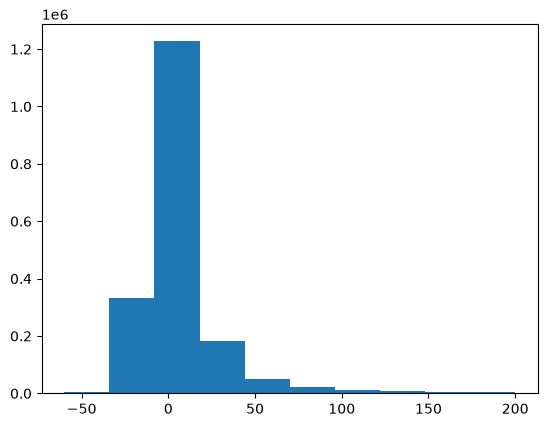

In [14]:
plt.hist(df["atraso_min"], range=(-60, 200))
plt.show

In [15]:
anterior_2024 = df[df["Partida Prevista"] < '2024-01-01']
anterior_2024

,ICAO Empresa Aérea,Número Voo,Código Autorização (DI),Código Tipo Linha,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,Situação Voo,Código Justificativa,atraso_min


In [16]:
posterior_2025 = df[df["Partida Prevista"] >= '2026-01-01']
posterior_2025.head()

,ICAO Empresa Aérea,Número Voo,Código Autorização (DI),Código Tipo Linha,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,Situação Voo,Código Justificativa,atraso_min
1905231,LTG,8431,0,G,SBSJ,SBKP,2026-01-01 08:05:00.100,NaT,2026-01-01 09:15:00.100,NaT,CANCELADO,NaN,NaN
1905997,LTG,8504,0,G,GVAC,EBBR,2026-01-01 07:10:00.100,NaT,2026-01-01 13:05:00.100,NaT,CANCELADO,NaN,NaN
1906007,LTG,8504,0,G,SBRF,GVAC,2026-01-01 01:45:00.100,NaT,2026-01-01 06:00:00.100,NaT,CANCELADO,NaN,NaN
1906382,ETH,0507,0,I,SBGR,HAAB,2026-01-01 01:30:00.100,2026-01-01 01:13:00,2026-01-01 13:30:00.100,2026-01-01 13:06:00,REALIZADO,NaN,-17.001667
1907569,ETH,3651,0,G,SBGR,SEQM,2026-01-01 04:00:00.100,NaT,2026-01-01 10:10:00.100,NaT,CANCELADO,NaN,NaN


In [17]:
posterior_2025.shape

(22, 13)

##### Retirar outliers encontrados (Alguns atrasos negativos e partidas em 2026)

# Cardinalidade alta

In [18]:
# Cardinalidade Alta é muitas categorias distintas
# mas o que vale não é o número de categorias é se cada categoria se repete o bastante para
# você confiar numa estatística 

#Identificador é quando a cardinalidade é tão alta que o valor aparece poucas vezes

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1992832 entries, 0 to 1992831
Data columns (total 13 columns):
 #   Column                   Dtype         
---  ------                   -----         
 0   ICAO Empresa Aérea       str           
 1   Número Voo               str           
 2   Código Autorização (DI)  string        
 3   Código Tipo Linha        str           
 4   ICAO Aeródromo Origem    str           
 5   ICAO Aeródromo Destino   str           
 6   Partida Prevista         datetime64[ns]
 7   Partida Real             datetime64[us]
 8   Chegada Prevista         datetime64[ns]
 9   Chegada Real             datetime64[us]
 10  Situação Voo             str           
 11  Código Justificativa     float64       
 12  atraso_min               float64       
dtypes: datetime64[ns](2), datetime64[us](2), float64(2), str(6), string(1)
memory usage: 247.4 MB


In [20]:
df.nunique()

ICAO Empresa Aérea            129
Número Voo                  11569
Código Autorização (DI)        10
Código Tipo Linha               4
ICAO Aeródromo Origem         467
ICAO Aeródromo Destino        480
Partida Prevista           265598
Partida Real               834216
Chegada Prevista           264771
Chegada Real               842975
Situação Voo                    2
Código Justificativa            0
atraso_min                   3687
dtype: int64

In [ ]:
df["Código Autorização (DI)"].value_counts(normalize=True)
# Dá para ver que 0 aparece em 96% do tempo, por isso é descartada para a previsão, é quase uma constante 0

Código Autorização (DI)
0    0.962209
2    0.010139
6    0.005729
1    0.004774
4    0.004469
9    0.004371
3    0.003932
7    0.003306
D    0.000861
E    0.000211
Name: proportion, dtype: double[pyarrow]

In [25]:
colunas_cat = ["ICAO Empresa Aérea", "ICAO Aeródromo Origem", "ICAO Aeródromo Destino", "Número Voo"]

for col in colunas_cat:
    contagem = df[col].value_counts()
    print("Categorias com menos de 5 valores:")
    col_unique = df[col].nunique()
    numero_menor_cinco = len(contagem[contagem <= 5].index)
    print(f"{col}: {col_unique}: {numero_menor_cinco}, [taxa: {(col_unique/numero_menor_cinco):.2f}]")

Categorias com menos de 5 valores:
ICAO Empresa Aérea: 129: 19, [taxa: 6.79]
Categorias com menos de 5 valores:
ICAO Aeródromo Origem: 467: 150, [taxa: 3.11]
Categorias com menos de 5 valores:
ICAO Aeródromo Destino: 480: 167, [taxa: 2.87]
Categorias com menos de 5 valores:
Número Voo: 11569: 3640, [taxa: 3.18]


In [ ]:
# Número Voo é retirado das features por redundancia
# Partida Real, Chegada Real, Situação Voo, Código Justificativa são pós-hoc,
# não servem para previsão


# Vazamento (atributos pós-hoc)
Só pode ser atributo o que é conhecido **antes do horário previsto de partida** (docs/metodologia.md §4.3). Quatro colunas do VRA só existem depois do voo: `Partida Real`, `Chegada Real`, `Situação Voo` e `Código Justificativa`. As células abaixo mostram, com os dados, por que cada uma vazaria o alvo.

In [ ]:
# Situação Voo: saber que o voo foi cancelado é saber que não existe Partida Real
pd.crosstab(df["Situação Voo"], df["Partida Real"].isna().rename("sem Partida Real"), margins=True)

#### Situação Voo e Partida Real andam juntas: todo cancelado está sem horário real, e todo realizado tem. A coluna só é preenchida depois do dia do voo.

In [ ]:
# Chegada Real: o atraso na chegada é quase o próprio alvo
atraso_chegada = (df["Chegada Real"] - df["Chegada Prevista"]).dt.total_seconds() / 60
validos = df["atraso_min"].between(-40, 720) & atraso_chegada.notna()

print(f"corr(atraso na partida, atraso na chegada) = {df.loc[validos, 'atraso_min'].corr(atraso_chegada[validos]):.3f}")
pd.crosstab(
    (df.loc[validos, "atraso_min"] >= 15).rename("partida atrasada"),
    (atraso_chegada[validos] >= 15).rename("chegada atrasada"),
    normalize="index",
).round(3)

#### Chegada Real: correlação de ~0,93 com o atraso na partida, e ~75% dos voos que partem atrasados chegam atrasados. Usar a chegada real seria entregar a resposta ao modelo. (`Chegada Prevista` continua permitida: é horário programado.)

In [ ]:
# Código Justificativa: é a explicação do atraso (vazamento total se estivesse preenchida)
print(f"Linhas com Código Justificativa preenchido em 2024-2025: {df['Código Justificativa'].notna().sum()}")

#### Código Justificativa está 100% vazia no período. Mesmo assim fica na lista de proibidas: se uma safra futura vier preenchida, ela é a justificativa do atraso, ou seja, o alvo explicado.

## A guarda: `assert_sem_vazamento`
A função de `src/data/clean.py` barra qualquer matriz de atributos que contenha uma coluna pós-hoc (incluindo `atraso_min` e `atrasado`). Ela é chamada sobre o X em `baselines.py` e em `gawll.py`. Abaixo, ela aprova a matriz de treino e barra a base bruta.

In [ ]:
import sys
sys.path.append("..")
from src.data.clean import assert_sem_vazamento
from src.models.baselines import NAO_ATRIBUTOS

x_treino = pd.read_parquet(Path("../data/processed/train.parquet")).drop(columns=NAO_ATRIBUTOS)
assert_sem_vazamento(x_treino)
print(f"Matriz de treino aprovada: {x_treino.shape[1]} atributos, nenhum pós-hoc")

try:
    assert_sem_vazamento(df)
except ValueError as erro:
    print(f"Base bruta barrada, como esperado: {erro}")

# Ano: por que não entra como feature
Com o split temporal (treino jan/2024–ago/2025, validação set–out/2025, teste nov–dez/2025), o ano é um atributo que **não generaliza além da fronteira do split**. As duas células abaixo mostram por quê. A taxa de atraso é calculada só até out/2025: o teste fica de fora (§4.9).

In [ ]:
# Em que ano cai cada conjunto do split (contagem de voos do bruto)
periodo = pd.cut(
    df["Partida Prevista"],
    bins=pd.to_datetime(["2024-01-01", "2025-09-01", "2025-11-01", "2026-01-01"]),
    right=False,
    labels=["treino", "validacao", "teste"],
)
pd.crosstab(periodo.rename("conjunto"), df["Partida Prevista"].dt.year.rename("ano"))

In [ ]:
# Taxa de atraso por mês, 2024 x 2025 (voos realizados, janela de plausibilidade, até out/2025)
realizados = df[
    (df["Situação Voo"] == "REALIZADO")
    & df["atraso_min"].between(-40, 720)
    & (df["Partida Prevista"] < "2025-11-01")
]
mes = realizados["Partida Prevista"].dt.month.rename("mes")
ano = realizados["Partida Prevista"].dt.year.rename("ano")
(realizados["atraso_min"] >= 15).groupby([mes, ano]).mean().unstack("ano").round(3)

#### Ano removido das features:
1. **Validação e teste são 100% 2025.** Dentro deles o ano é constante. O modelo só aprenderia a diferença 2024 × 2025 no treino, e essa diferença nunca seria testada.
2. **Não é um efeito estável.** O "efeito 2025" muda de sinal conforme o mês (jan: 0,231 → 0,177; abr: 0,155 → 0,170). Um atributo de ano capturaria ruído de nível entre anos, não um padrão operacional.
3. **Contaminaria o objeto do TCC.** Um atributo espúrio com importância alta distorceria os rankings de importância que o trabalho compara.

A sazonalidade real (mês, dia do ano, feriados) continua coberta por `mes`, `dia_ano`, `trimestre`, `feriado` e `vespera_feriado`.